# Figure 3 — Phase portrait of a point-charge electron in a harmonic field

Isoenergy contours of the pendulum-like classical dynamics,

$$
\delta_v=\pm\sqrt{2\left(\frac{\varepsilon_0}{\omega^2}-\frac{\Omega^2}{\omega^2}\cos\varphi\right)},
$$

for a set of values of $\varepsilon_0$, with $\Omega^2/\omega^2=5.3\times10^{-6}$
(1064 nm light, $E_0=4$ MV/m, parallel wave vector $k=n\omega/c$ with $n=4$).

* **(a)** periodic phase portrait; the separatrix $\varepsilon_0=\Omega^2$ divides closed and open contours;
* **(b, c)** the same contours over one period, together with the horizontal line of initial conditions
  $\delta_v=\delta_{v,0}$ and the extreme mismatches $\delta_{v,\max}$, $\delta_{v,\min}$ predicted by the analytical
  bounds of the paper. ($\delta_{v,0}$ = 0.6 % in (b) and 0.25 % in (c); the hand-drawn trajectory arrows of the published
  figure are illustrative and are not reproduced.)

**Data files** (plain-text CSV, see `data/README.md`): `data/fig3/fig3_contours.csv` (contours $\delta_v(\varphi)$),
`data/fig3/fig3bc_bounds.csv` (red lines and markers of b, c), `data/fig3/fig3_parameters.csv`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import m_e, e, c
import pinem_recoil as pr

DATA = Path("data") / "fig3"
FIGS = Path("figures")
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False

## Parameters

In [2]:
E0 = 4e6
wavelength = 1064e-9
n = 4
omega = 2 * np.pi * c / wavelength
k = omega / (c / n)
Omega_sq = e * k * E0 / m_e                       # Omega^2
r = Omega_sq / omega**2                            # Omega^2 / omega^2
eps_over_Omega_sq = np.array([-0.9999, -0.9, -0.41, 0.508, 1, 1.589, 2.395, 3.233, 4.395, 5.5])
phi = np.linspace(-2.1 * np.pi, 2.1 * np.pi, 5001)
delta_v0 = {"b": 0.006, "c": 0.0025}               # initial mismatch in panels (b), (c)
print(f"Omega^2/omega^2 = {r:.2e}")

Omega^2/omega^2 = 5.30e-06


## Computation

In [3]:
file_c = DATA / "fig3_contours.csv"
file_b = DATA / "fig3bc_bounds.csv"
file_par = DATA / "fig3_parameters.csv"
if RECOMPUTE or not all(f.exists() for f in [file_c, file_b, file_par]):
    cols = {"phi_rad": phi}
    for x in eps_over_Omega_sq:
        arg = 2 * r * (x - np.cos(phi))           # 2 (eps0 - Omega^2 cos(phi)) / omega^2
        dv = np.where(arg >= 0, np.sqrt(np.clip(arg, 0, None)), np.nan)
        cols[f"delta_v_plus_eps={x:g}Omega^2"] = dv
        cols[f"delta_v_minus_eps={x:g}Omega^2"] = -dv
    pr.save_columns(file_c, **cols)
    rows = []
    for panel, d0 in delta_v0.items():
        d_max = np.sqrt(d0**2 + 4 * r)
        d_min = np.sqrt(d0**2 - 4 * r) if d0 >= 2 * np.sqrt(r) else -np.sqrt(4 * r)
        rows.append([d0, d_max, d_min])
    rows = np.array(rows)
    pr.save_columns(file_b, panel=list(delta_v0), delta_v0=rows[:, 0], delta_v_max=rows[:, 1],
                    delta_v_min=rows[:, 2])
    pr.save_parameters(file_par, [
        ("Omega_sq_over_omega_sq", r, "Omega^2/omega^2"),
        ("wavelength_m", wavelength, "light wavelength"),
        ("E0_V_per_m", E0, "field amplitude"),
        ("n", n, "parallel wave vector k = n omega/c"),
    ])
    print("saved", file_c, file_b, file_par)

saved data\fig3\fig3_contours.csv data\fig3\fig3bc_bounds.csv data\fig3\fig3_parameters.csv


## Load data and plot

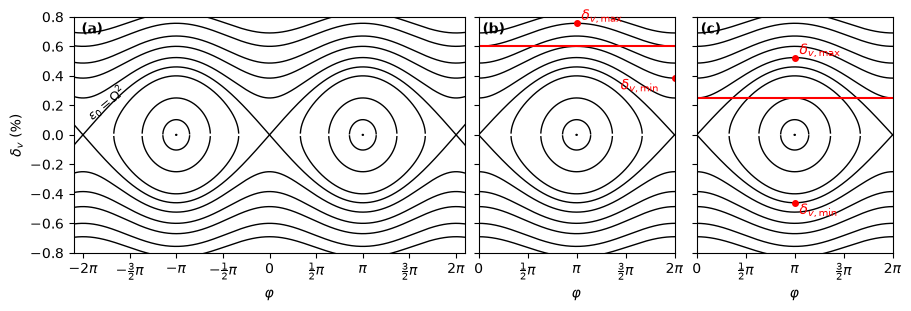

In [4]:
C = pr.load_columns(file_c)
B = pr.load_columns(file_b)
bounds = np.column_stack([B["delta_v0"], B["delta_v_max"], B["delta_v_min"]])
names = list(C)
phi_d = C["phi_rad"]

fig = plt.figure(figsize=(9, 3), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[2, 1, 1])
axs = [fig.add_subplot(gs[i]) for i in range(3)]
for ax in axs:
    for name in names[1:]:
        ax.plot(phi_d, C[name] * 100, "k-", lw=1)
    ax.set_ylim(-0.8, 0.8)
    ax.set_xlabel(r"$\varphi$")
axs[0].set_xlim(-2.1 * np.pi, 2.1 * np.pi)
axs[0].set_xticks(np.arange(-2, 2.5, 0.5) * np.pi,
                  [r"$-2\pi$", r"$-\frac{3}{2}\pi$", r"$-\pi$", r"$-\frac{1}{2}\pi$", "0",
                   r"$\frac{1}{2}\pi$", r"$\pi$", r"$\frac{3}{2}\pi$", r"$2\pi$"])
axs[0].set_ylabel(r"$\delta_v$ (%)")
axs[0].text(-1.98 * np.pi, 0.1, r"$\varepsilon_0=\Omega^2$", rotation=40, fontsize=9)
for ax, (panel, row) in zip(axs[1:], zip("bc", bounds)):
    d0, dmax, dmin = row * 100
    ax.set_xlim(0, 2 * np.pi)
    ax.set_xticks(np.arange(0, 2.5, 0.5) * np.pi, ["0", r"$\frac{1}{2}\pi$", r"$\pi$", r"$\frac{3}{2}\pi$", r"$2\pi$"])
    ax.set_yticklabels([])
    ax.axhline(d0, color="r", lw=1.5)
    ax.plot([np.pi], [dmax], "ro", ms=4)
    ax.plot([np.pi if dmin < 0 else 2 * np.pi], [dmin], "ro", ms=4)
    ax.text(np.pi + 0.15, dmax + 0.02, r"$\delta_{v,\max}$", color="r")
    ax.text(np.pi + 0.15 if dmin < 0 else 1.45 * np.pi, dmin - 0.08, r"$\delta_{v,\min}$", color="r")
for ax, lab in zip(axs, "abc"):
    ax.text(0.02, 0.93, f"({lab})", transform=ax.transAxes, fontweight="bold")
fig.savefig(FIGS / "fig3.png", dpi=200)
fig.savefig(FIGS / "fig3.pdf")
plt.show()